## Constrained-area navigation adjustment (Flag 17)

### Dataset Overview
Paired normal and constrained trajectories for 44 vessels in an offshore west-Jutland corridor. The restriction geometry and effective interval are supplied as an independent supporting table.

The notebook exposes a primary table and a supporting table (`constrained_area.csv`).

Goal: Analyze how vessels adjust their movements when navigating around the constrained area.

Role: Maritime traffic analyst


Category: constrained-area navigation adjustment

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "constrained_area.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do vessels bypass and rejoin traffic around the constrained area?

#### Analysis action

Join the independent constrained-area boundary with paired normal and constrained trajectories, then identify bypass side and rejoining geometry.

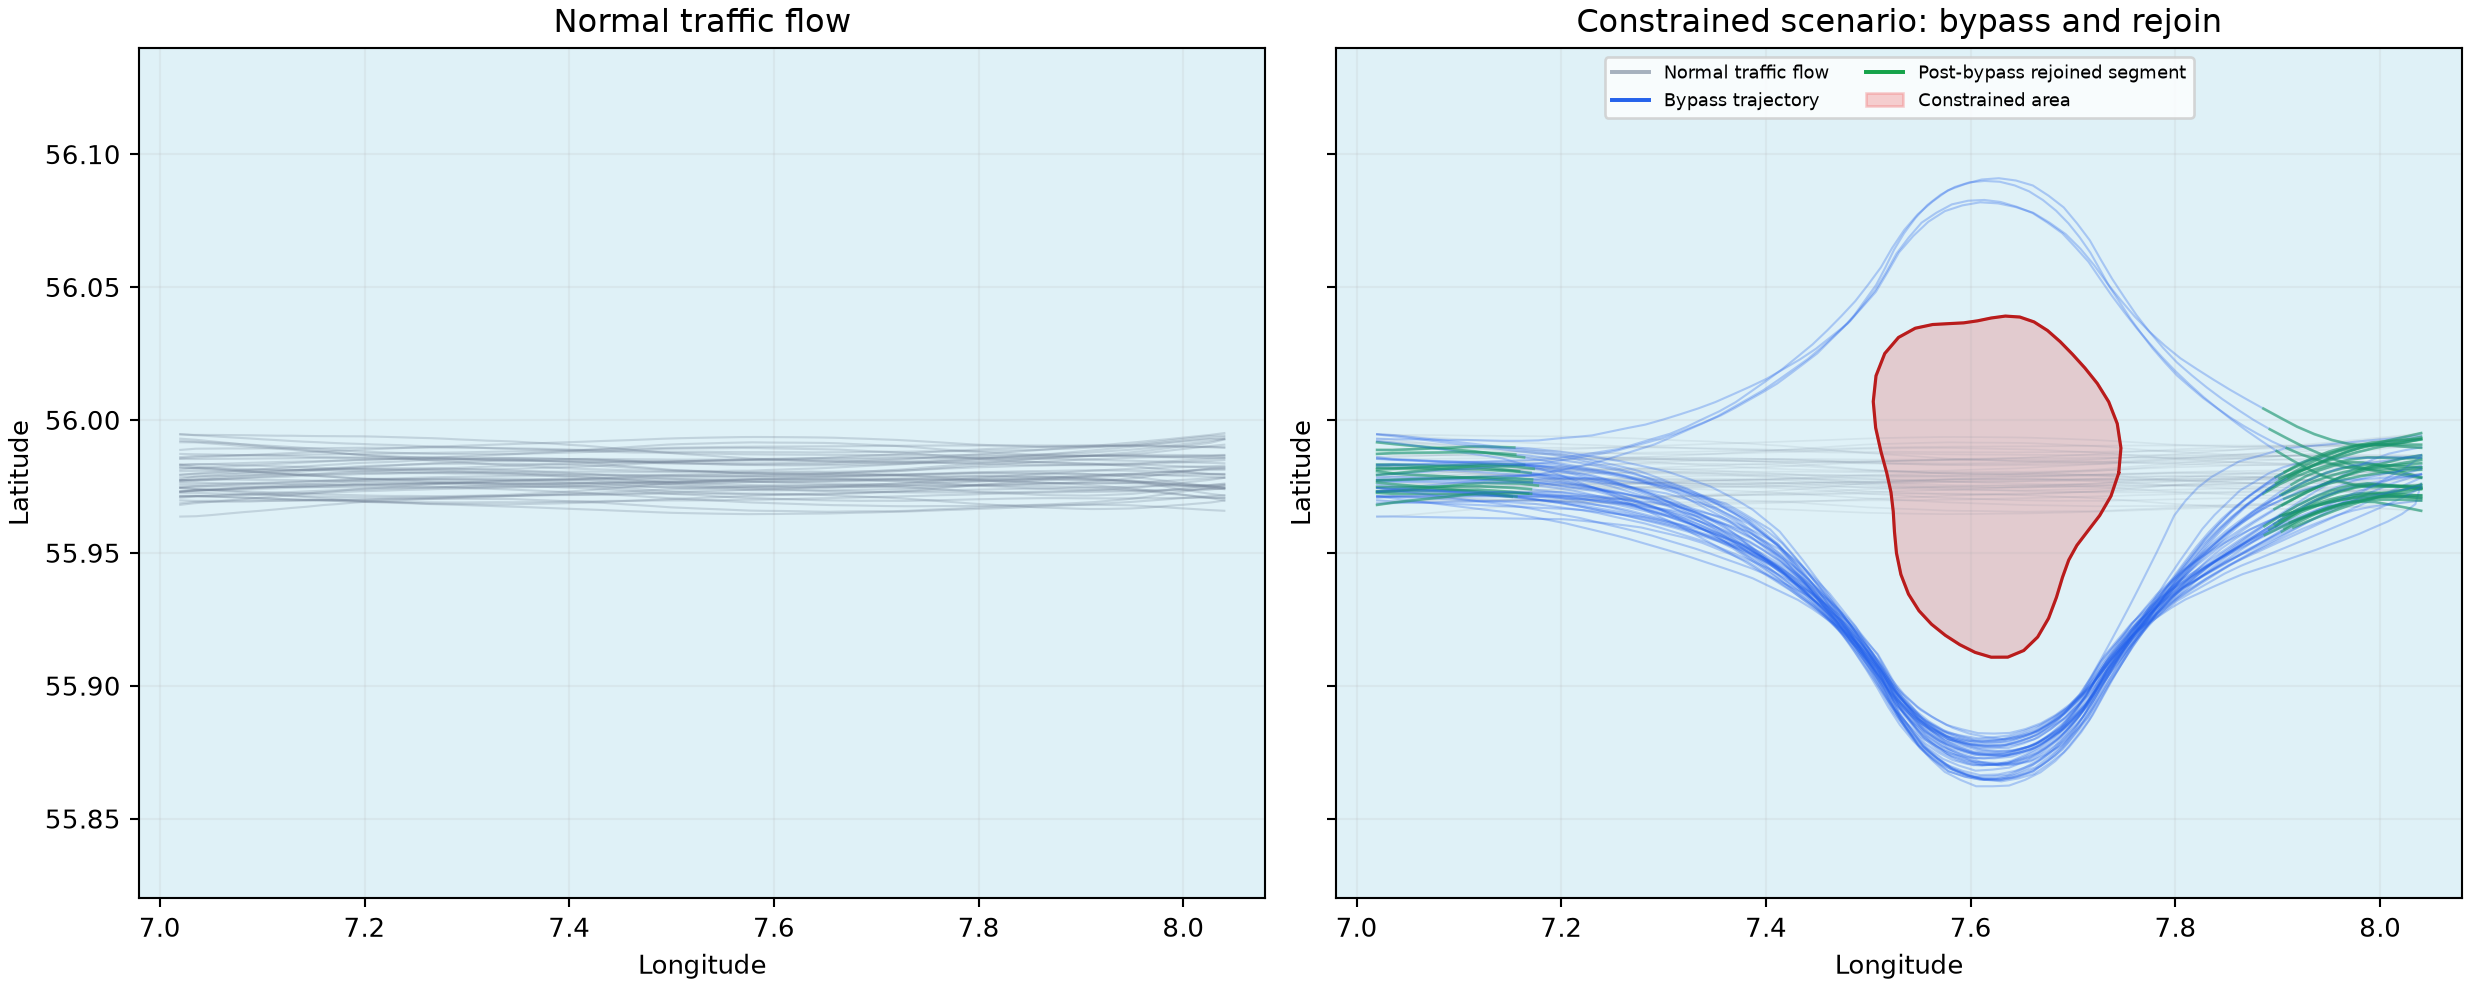

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); area=pd.read_csv(user_dataset_path); print(area[['area_id','restriction_type','effective_start','effective_end']].drop_duplicates()); print(df.groupby(['scenario','trajectory_id']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/constraint_bypass_overview.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "constraint_bypass_pattern",
  "insight": "Most vessels bypass the constrained area along a consistent side and gradually rejoin the main traffic flow after passing it.",
  "insight_value": {
    "bypass_side_counts": {
      "south": 40,
      "north": 4
    },
    "rejoined_within_1km_count": 44,
    "total_constrained_trajectories": 44,
    "median_post_rejoin_lateral_offset_km": 0.25,
    "trajectories_with_backward_steps": 0
  },
  "plot": {
    "plot_type": "scenario_comparison_map",
    "title": "Navigation Around a Constrained Area",
    "file": "visualizations/constraint_bypass_overview.png",
    "description": "Join the independent constrained-area boundary with paired normal and constrained trajectories, then identify bypass side and rejoining geometry."
  },
  "question": "How do vessels bypass and rejoin traffic around the constrained area?",
  "actionable_insight": "Join the independent constrained-area boundary with paired normal and constrained trajectories, then identify bypass side and rejoining geometry.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); area=pd.read_csv(user_dataset_path); print(area[['area_id','restriction_type','effective_start','effective_end']].drop_duplicates()); print(df.groupby(['scenario','trajectory_id']).size())",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "constrained_area",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How do heading and COG change during constrained-area avoidance?

#### Analysis action

Use the independent boundary to locate the approach and align constrained tracks around their principal turn before comparing heading with COG progression.

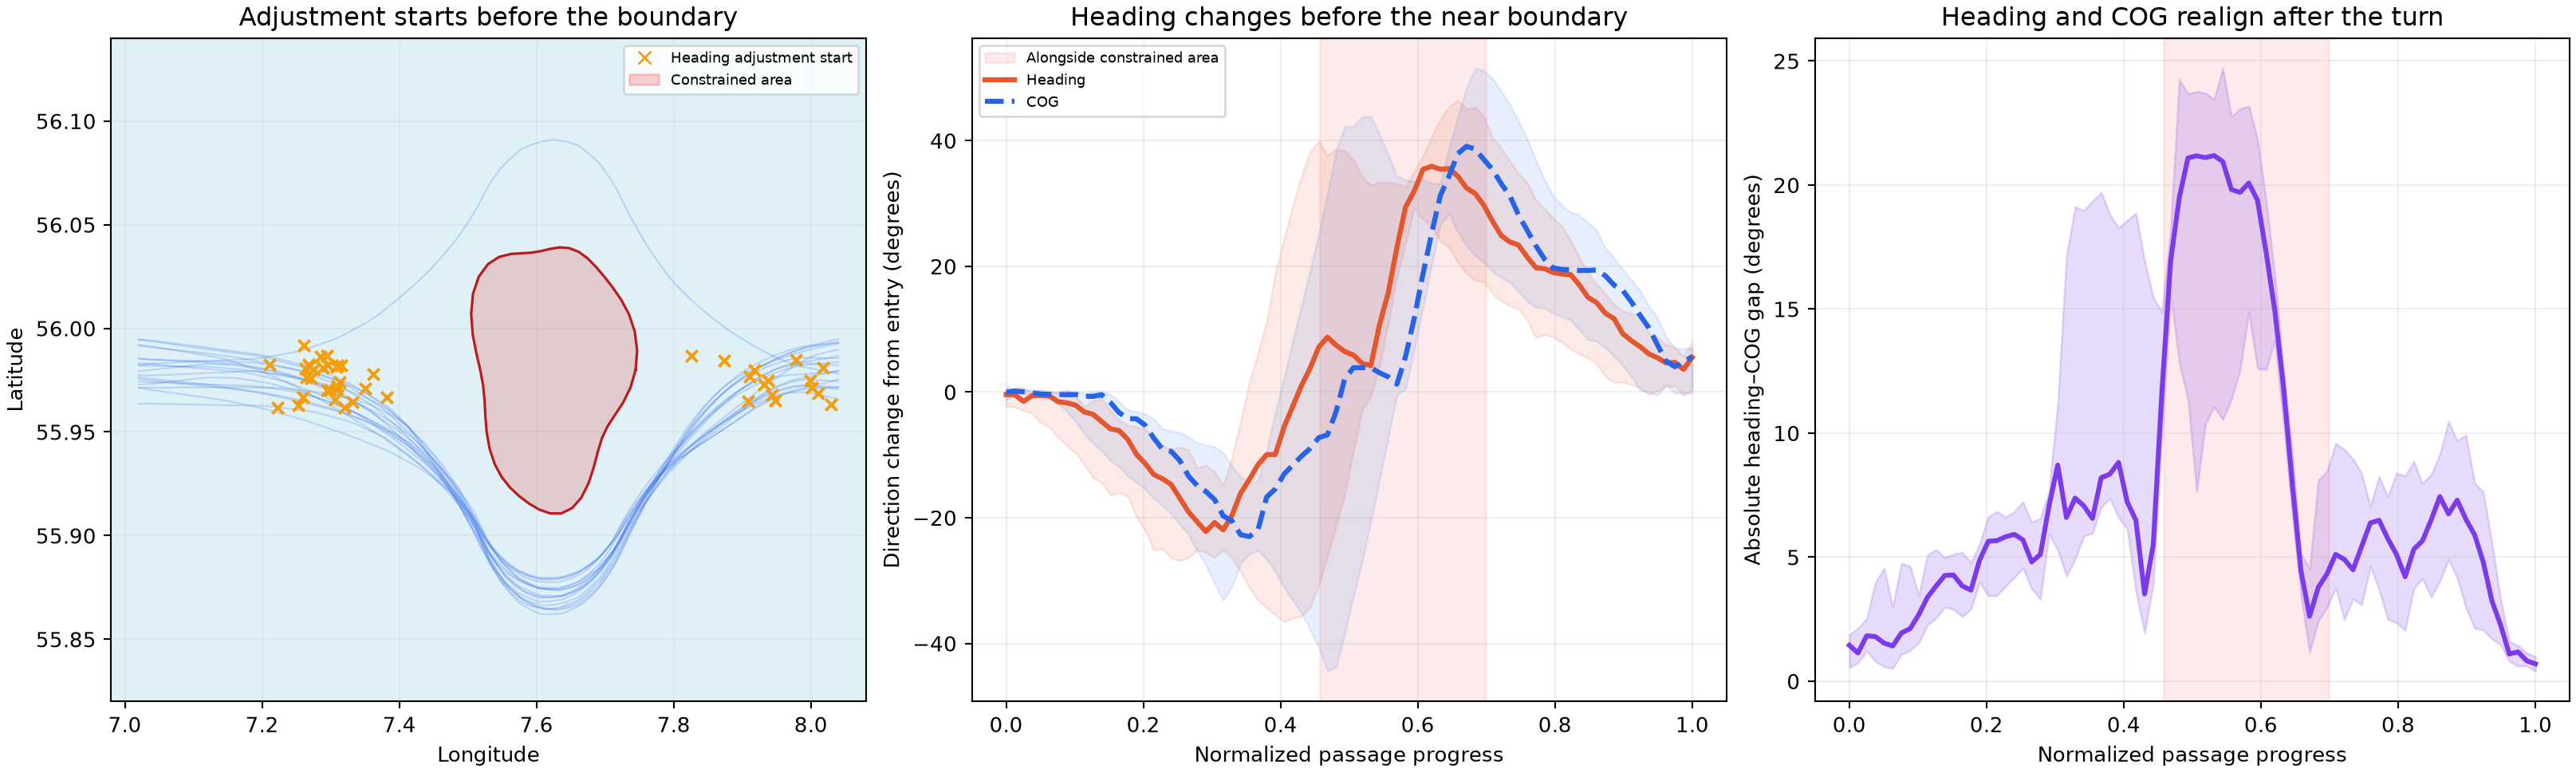

In [ ]:
import pandas as pd, numpy as np
df=pd.read_csv(dataset_path); area=pd.read_csv(user_dataset_path); df['gap']=abs((df.heading-df.cog+180)%360-180); print(area[['lat','lon']].describe()); print(df.groupby('scenario').gap.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/heading_cog_turn_sequence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "heading_cog_adjustment_sequence",
  "insight": "Most vessels begin changing their heading before reaching the constrained area, while the corresponding COG changes more gradually and realigns with heading after the main turn is completed.",
  "insight_value": {
    "median_whole_passage_gap_deg": 4.67,
    "median_turn_p90_gap_deg": 17.66,
    "median_adjustment_lead_to_boundary_km": 11.84
  },
  "plot": {
    "plot_type": "aligned_turn_profile",
    "title": "Heading and COG Through the Turn",
    "file": "visualizations/heading_cog_turn_sequence.png",
    "description": "Use the independent boundary to locate the approach and align constrained tracks around their principal turn before comparing heading with COG progression."
  },
  "question": "How do heading and COG change during constrained-area avoidance?",
  "actionable_insight": "Use the independent boundary to locate the approach and align constrained tracks around their principal turn before comparing heading with COG progression.",
  "code": "import pandas as pd, numpy as np\ndf=pd.read_csv(dataset_path); area=pd.read_csv(user_dataset_path); df['gap']=abs((df.heading-df.cog+180)%360-180); print(area[['lat','lon']].describe()); print(df.groupby('scenario').gap.describe())",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "constrained_area",
    "heading",
    "course_over_ground",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Does adjustment distance vary with vessel speed?

#### Analysis action

Compare continuous vessel speed with the distance at which avoidance begins, retaining realistic overlap.

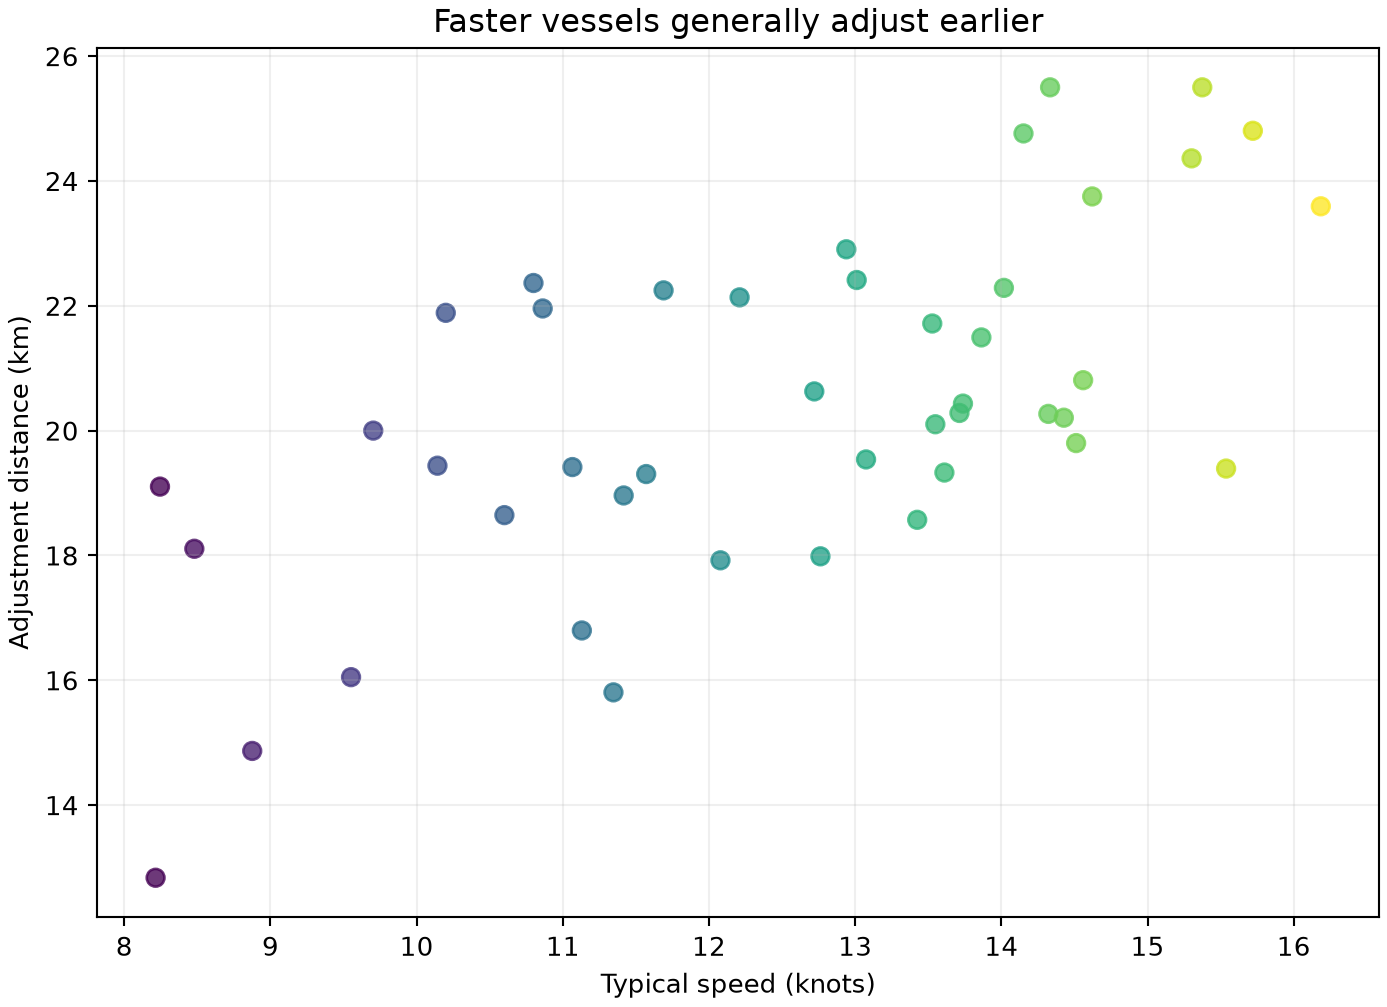

In [ ]:
import pandas as pd
print(pd.read_csv(dataset_path).groupby(['vessel_id','scenario']).sog_knots.mean())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_adjustment_distance.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_adjustment_distance_relationship",
  "insight": "Faster-moving vessels tend to initiate their course adjustment farther from the constrained area, while slower vessels make comparable directional changes closer to its boundary.",
  "insight_value": {
    "spearman_rho": 0.604,
    "median_adjustment_distance_km": {
      "slower_half": 19.2,
      "faster_half": 21.15
    }
  },
  "plot": {
    "plot_type": "scatter_distribution",
    "title": "Speed and Adjustment Distance",
    "file": "visualizations/speed_adjustment_distance.png",
    "description": "Compare continuous vessel speed with the distance at which avoidance begins, retaining realistic overlap."
  },
  "question": "Does adjustment distance vary with vessel speed?",
  "actionable_insight": "Compare continuous vessel speed with the distance at which avoidance begins, retaining realistic overlap.",
  "code": "import pandas as pd\nprint(pd.read_csv(dataset_path).groupby(['vessel_id','scenario']).sog_knots.mean())",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "constrained_area",
    "point_speed",
    "course_over_ground",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 17)

Most vessels bypass the constrained area along a consistent side and gradually rejoin the main traffic flow after passing it. Most vessels begin changing their heading before reaching the constrained area, while the corresponding COG changes more gradually and realigns with heading after the main turn is completed. Faster-moving vessels tend to initiate their course adjustment farther from the constrained area, while slower vessels make comparable directional changes closer to its boundary.